# LO2v2 log intelligence

Use the token service log for four known scenarios across the ten metric runs: correct, bad request, unauthorized, and not found. The downloader reads selected members from the official ZIP and caps the download volume. For each log, the parser identifies a log level and logger name, replaces variable-looking fields in the message, and hashes the resulting template. The first 128 parsed events form the sequence. Raw messages are not saved by the sampler.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
cache = root / "data/interim/log_templates.json"
if not cache.exists():
    subprocess.run([sys.executable, "-m", "src.log_sample"], cwd=root, check=True)
subprocess.run([sys.executable, "-m", "src.log_intelligence"], cwd=root, check=True)
results = root / "results"
summary = json.loads((results / "log_sample_summary.json").read_text())
display(pd.Series(summary))

compressed_member_bytes                                                4453731
events_per_document                                                        128
documents_by_split                   {'train': 24, 'validation': 8, 'test': 8}
train_vocabulary_size                                                       38
train_most_common_template_counts                    [809, 574, 287, 274, 249]
test_error_prevalence                                                     0.75
test_runs                                                                    2
dtype: object

## Compare logs, metrics, and late fusion

The TF-IDF baseline uses template frequencies and logistic regression. The Transformer learns 24-dimensional template embeddings, uses four-head attention over the 128 events and mean-pools the sequence for binary prediction. Validation loss selects the Transformer checkpoint. The metric baseline uses scenario-level median window features joined to logs on run and scenario. Late fusion averages the template and metric scores with equal weights. Each evaluation example is a run-scenario pair.

The held-out sample contains two runs with the same four scenario types seen during training. These results measure transfer across executions of known scenarios. They do not estimate performance on novel errors, other services, or a production stream.

,roc_auc,average_precision,balanced_accuracy_at_0_5
model,,,
Log templates,1.000,1.000,1.000
Log Transformer,1.000,1.000,0.917
Metrics Random Forest,0.667,0.911,0.333
Late fusion,0.667,0.911,0.333


,run,test,error,Log templates,Log Transformer,Metrics Random Forest,Late fusion
0,LO2_run_1738661358,correct,False,0.482,0.268,0.520,0.501
1,LO2_run_1738661358,access_token_form_urlencoded_400,True,0.520,0.753,0.420,0.470
2,LO2_run_1738661358,access_token_authorization_form_401,True,0.519,0.525,0.635,0.577
3,LO2_run_1738661358,get_token_404,True,0.503,0.439,0.575,0.539
4,LO2_run_1739484002,correct,False,0.476,0.234,0.535,0.506
5,LO2_run_1739484002,access_token_form_urlencoded_400,True,0.517,0.694,0.640,0.579
6,LO2_run_1739484002,access_token_authorization_form_401,True,0.509,0.521,0.765,0.637
7,LO2_run_1739484002,get_token_404,True,0.519,0.628,0.475,0.497


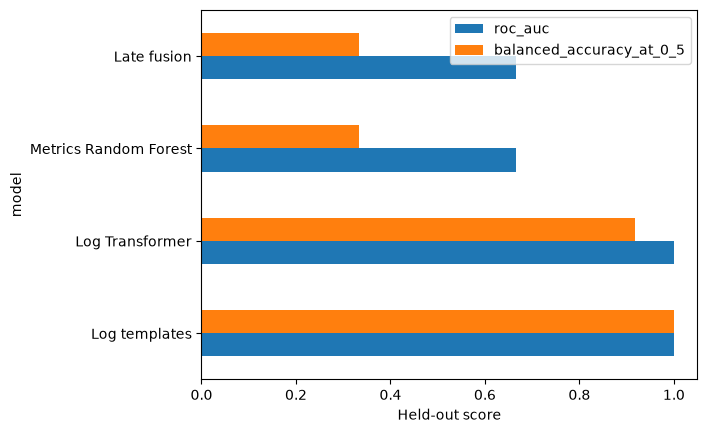

In [2]:
evaluation = pd.read_csv(results / "log_model_metrics.csv").set_index("model")
predictions = pd.read_csv(results / "log_predictions.csv")
assert len(predictions) == summary["documents_by_split"]["test"]
assert predictions.run.nunique() == summary["test_runs"]
display(evaluation.round(3))
display(predictions.round(3))

ax = evaluation[["roc_auc", "balanced_accuracy_at_0_5"]].plot.barh(xlim=(0, 1.05))
ax.set_xlabel("Held-out score")
plt.show()